<a href="https://colab.research.google.com/github/Eslam-Emad27/daily_sales/blob/main/sales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

===== Summary Statistics =====
                      date   quantity  unit_price       total
count                   30  30.000000   30.000000   30.000000
mean   2025-01-15 12:00:00   4.966667   33.333333  161.000000
min    2025-01-01 00:00:00   1.000000   20.000000   30.000000
25%    2025-01-08 06:00:00   3.000000   20.000000   90.000000
50%    2025-01-15 12:00:00   5.000000   30.000000  150.000000
75%    2025-01-22 18:00:00   6.750000   50.000000  195.000000
max    2025-01-30 00:00:00   9.000000   50.000000  400.000000
std                    NaN   2.311640   12.685407   95.316171

===== Total Sales by Product =====
product
Product A    2200
Product B    1590
Product C    1040
Name: total, dtype: int64

Best-selling product: Product A with total 2200



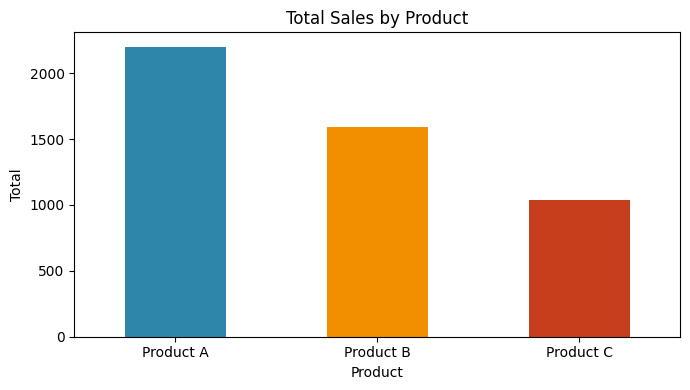

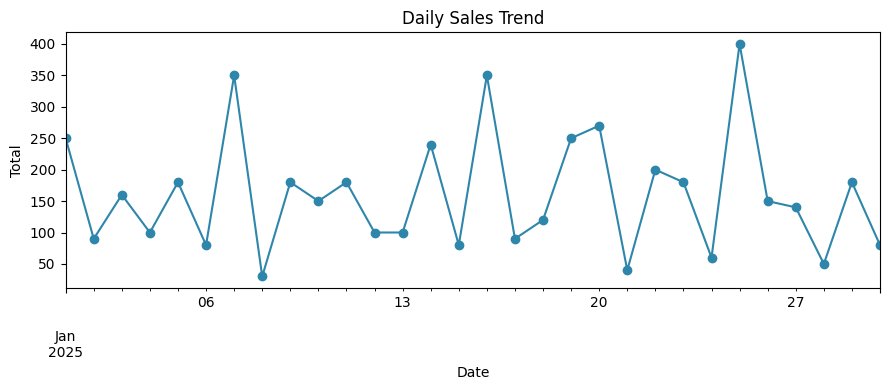

Report saved to sales_summary_report_en.csv


In [2]:


import pandas as pd
import matplotlib.pyplot as plt

data = {
    "date": pd.date_range(start="2025-01-01", periods=30, freq="D"),
    "product": ["Product A", "Product B", "Product C"] * 10,
    "quantity": [5, 3, 8, 2, 6, 4, 7, 1, 9, 3,
                 6, 5, 2, 8, 4, 7, 3, 6, 5, 9,
                 2, 4, 6, 3, 8, 5, 7, 1, 6, 4],
    "unit_price": [50, 30, 20, 50, 30, 20, 50, 30, 20, 50,
                   30, 20, 50, 30, 20, 50, 30, 20, 50, 30,
                   20, 50, 30, 20, 50, 30, 20, 50, 30, 20],
}

df = pd.DataFrame(data)

df["total"] = df["quantity"] * df["unit_price"]

df = df.drop_duplicates()
df = df.dropna()

print("===== Summary Statistics =====")
print(df.describe())
print()

sales_by_product = df.groupby("product")["total"].sum().sort_values(ascending=False)
print("===== Total Sales by Product =====")
print(sales_by_product)
print()

top_product = sales_by_product.idxmax()
print(f"Best-selling product: {top_product} with total {sales_by_product.max()}")
print()

plt.figure(figsize=(7, 4))
sales_by_product.plot(kind="bar", color=["#2E86AB", "#F18F01", "#C73E1D"])
plt.title("Total Sales by Product")
plt.ylabel("Total")
plt.xlabel("Product")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("sales_by_product_en.png", dpi=150)
plt.show()

daily_sales = df.groupby("date")["total"].sum()
plt.figure(figsize=(9, 4))
daily_sales.plot(kind="line", marker="o", color="#2E86AB")
plt.title("Daily Sales Trend")
plt.ylabel("Total")
plt.xlabel("Date")
plt.tight_layout()
plt.savefig("daily_sales_trend_en.png", dpi=150)
plt.show()

sales_by_product.to_csv("sales_summary_report_en.csv", encoding="utf-8-sig")
print("Report saved to sales_summary_report_en.csv")